# Linear-drag trajectory baseline

Despite the filename, this is not a vacuum/no-drag idealization: it includes linear drag (`a_drag = -k v`) and gravity. Launch velocity and `k` are fitted to the two measured positions; the goal crossing uses the event-interpolated state.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.stats import chi2

In [2]:
# Linear-drag baseline fitted to the two observed positions.
g = 9.81
m = 0.43  # Ball mass used only for the mechanical-energy plot
r0 = np.array([0.0, 0.0, 0.11])
r1 = np.array([1.50, 0.45, 0.44])
r2 = np.array([2.96, 0.86, 0.74])
dt = 0.05
observation_times = np.array([dt, 2 * dt])
sigma_position = 0.005  # Assumed coordinate standard deviation (m)
v0 = (4 * r1 - r2 - 3 * r0) / (2 * dt)  # Initial fit guess only
k = 0.5  # Initial fit guess (1/s)

In [3]:
state0 = np.concatenate((r0, v0))

In [4]:
def equations_of_motion(t, state, k_value):
    x, y, z, vx, vy, vz = state
    return [vx, vy, vz, -k_value * vx, -k_value * vy, -g - k_value * vz]

In [5]:
def observation_residual(parameters):
    initial_state = np.concatenate((r0, parameters[:3]))
    fit_sol = solve_ivp(
        lambda time, state: equations_of_motion(time, state, parameters[3]),
        (0.0, observation_times[-1]), initial_state,
        t_eval=observation_times, max_step=0.002, rtol=1e-8, atol=1e-10,
    )
    if not fit_sol.success or fit_sol.y.shape[1] != len(observation_times):
        raise RuntimeError(f"Observation integration failed: {fit_sol.message}")
    return ((fit_sol.y[:3, :].T - np.vstack((r1, r2))) / sigma_position).ravel()

fit = least_squares(
    observation_residual, np.concatenate((v0, [k])),
    bounds=(np.array([-np.inf, -np.inf, -np.inf, 1e-8]), np.full(4, np.inf)),
    x_scale="jac", max_nfev=100,
)
if not fit.success:
    raise RuntimeError(f"Linear-drag fit failed: {fit.message}")
v0, k = fit.x[:3], fit.x[3]
state0 = np.concatenate((r0, v0))


def hit_goal_plane(time, state):
    return state[0] - 11.0


hit_goal_plane.terminal = True
hit_goal_plane.direction = 1
sol = solve_ivp(
    lambda time, state: equations_of_motion(time, state, k),
    (0.0, 1.0), state0, events=hit_goal_plane,
    max_step=0.002, rtol=1e-8, atol=1e-10,
)
if not sol.success:
    raise RuntimeError(f"Goal integration failed: {sol.message}")
if len(sol.t_events[0]) == 0:
    raise RuntimeError("The fitted trajectory did not reach the goal plane.")

t_goal = sol.t_events[0][0]
impact_state = sol.y_events[0][0]
t = sol.t.copy()
trajectory = sol.y.T.copy()
if not np.isclose(t[-1], t_goal):
    t = np.append(t, t_goal)
    trajectory = np.vstack((trajectory, impact_state))
x, y, z = trajectory[:, 0], trajectory[:, 1], trajectory[:, 2]
vx, vy, vz = trajectory[:, 3], trajectory[:, 4], trajectory[:, 5]
y_goal, z_goal = impact_state[1], impact_state[2]
residuals = -observation_residual(fit.x).reshape(2, 3) * sigma_position
fit_rmse = np.sqrt(np.mean(residuals**2))
fit_chi2 = np.sum((residuals / sigma_position) ** 2)
fit_dof = residuals.size - fit.x.size
print("LINEAR-DRAG BASELINE FIT")
print(f"Fitted launch velocity: ({v0[0]:.4f}, {v0[1]:.4f}, {v0[2]:.4f}) m/s")
print(f"Fitted linear-drag coefficient k: {k:.5f} 1/s")
print(f"Observed - fitted position residuals (mm):\n{(1000 * residuals).round(2)}")
print(f"Coordinate fit RMSE: {1000 * fit_rmse:.2f} mm (assumed sigma = {1000*sigma_position:.1f} mm)")
print(f"Noise-only fit diagnostic: chi-square={fit_chi2:.2f}, dof={fit_dof}, p={chi2.sf(fit_chi2, fit_dof):.4f}")
print(f"Goal crossing: t={t_goal:.4f} s, y={y_goal:.3f} m, z={z_goal:.3f} m")
print("The fit is conditional on the linear-drag model and the fixed initial position.")

LINEAR-DRAG BASELINE FIT
Fitted launch velocity: (30.5313, 8.9297, 6.9876) m/s
Fitted linear-drag coefficient k: 0.63212 1/s
Observed - fitted position residuals (mm):
[[-2.69 10.5  -1.78]
 [ 1.37 -5.33  0.9 ]]
Coordinate fit RMSE: 5.03 mm (assumed sigma = 5.0 mm)
Noise-only fit diagnostic: chi-square=6.07, dof=2, p=0.0481
Goal crossing: t=0.4088 s, y=3.217 m, z=1.874 m
The fit is conditional on the linear-drag model and the fixed initial position.


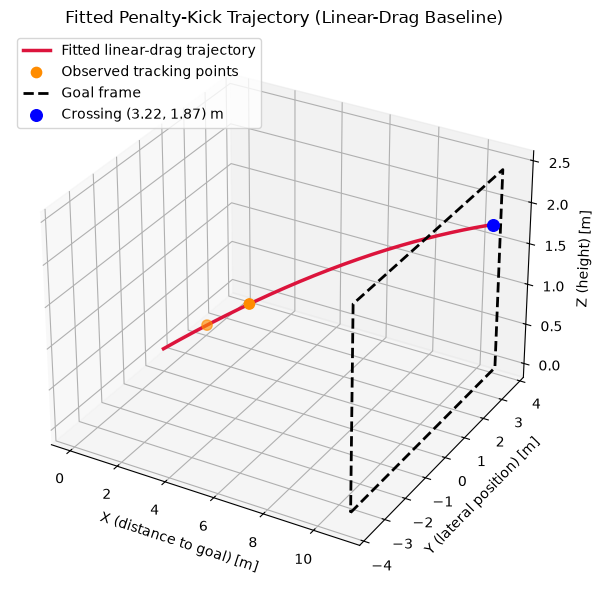

In [6]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(x, y, z, color="crimson", linewidth=2.5, label="Fitted linear-drag trajectory")
ax.scatter([r1[0], r2[0]], [r1[1], r2[1]], [r1[2], r2[2]], color="darkorange", s=55, label="Observed tracking points")
goal_y = [-3.66, 3.66, 3.66, -3.66, -3.66]
goal_z = [0.0, 0.0, 2.44, 2.44, 0.0]
ax.plot([11.0] * 5, goal_y, goal_z, color="black", linewidth=2, linestyle="--", label="Goal frame")
ax.scatter([11.0], [y_goal], [z_goal], color="blue", s=70, label=f"Crossing ({y_goal:.2f}, {z_goal:.2f}) m")
ax.set_xlabel("X (distance to goal) [m]")
ax.set_ylabel("Y (lateral position) [m]")
ax.set_zlabel("Z (height) [m]")
ax.set_title("Fitted Penalty-Kick Trajectory (Linear-Drag Baseline)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [7]:
v_sq = vx**2 + vy**2 + vz**2
E_kinetic = 0.5 * m * v_sq
E_potential = m * g * z
E_total = E_kinetic + E_potential

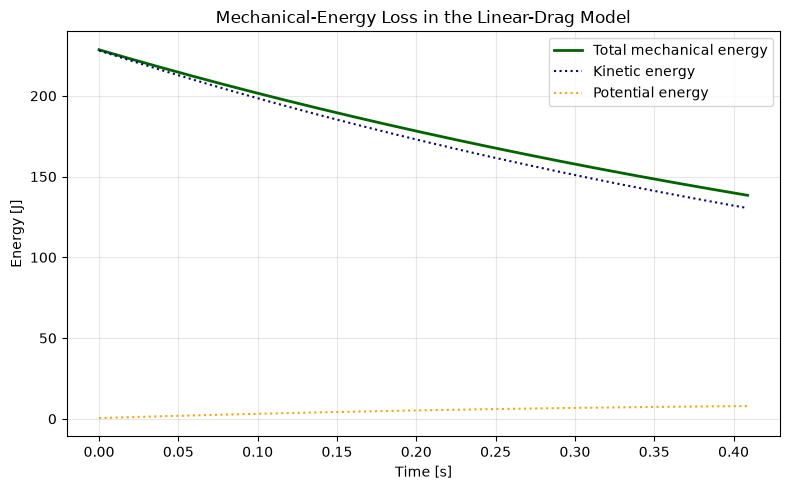

In [8]:
fig, ax2 = plt.subplots(figsize=(8, 5))
ax2.plot(t, E_total, color="darkgreen", linewidth=2, label="Total mechanical energy")
ax2.plot(t, E_kinetic, color="navy", linestyle=":", label="Kinetic energy")
ax2.plot(t, E_potential, color="orange", linestyle=":", label="Potential energy")
ax2.set_xlabel("Time [s]")
ax2.set_ylabel("Energy [J]")
ax2.set_title("Mechanical-Energy Loss in the Linear-Drag Model")
ax2.grid(True, alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()